# Uczenie Maszynowe - Projekt "Kidney Tumor Radiomics"

## Wstęp
Mój projekt opiera się na sieci CNN której zadaniem jest ocena nowotworów nerki, na bazie segmentacji 3D nerka-nowotór.

Zdecydowałem, po moich wcześniejszych i dzisiejszych trudnościach z ICM, że projekt będzie korzystał wyłacznie z plików .py.
Z wyjątkiem skryptów do analizy danych, które pisałem w notebookach, gdyż nie wymagają one znaczącej mocy obliczeniowej.

W związku z tym przedstawię projekt, poprzez kopiowanie tych plików bezpośrednio do .ipynb.

## Definicja danych wejściowych i wyjściowych
Dane wejściowe, pochodzą z zbioru danych z konkursu KiTS23, które zostały przekształcone. Więcej informacji o konkursie tutaj: https://kits-challenge.org/kits23/.

Dane wyjściowe pochodzą z annotacj ręcznej doktorów medycznych specjalizujących się w urologi, z którymi współpracuję.

### Dane wejściowe wstępne
Nie pokażę tego bezpośrednio tutaj (gdyż to wymaga pobrania i odpalenia oddzielnego repo), pobrać je można podążając z instrukcjami z https://github.com/neheller/kits23.

Z tego zbioru danych mamy 489 case-ów, każdy z nich zawiera skan, segmentację ogólną (ze wszystkim 3 typami oznaczeń) oraz indywidualne segmentacje do każdej instancj oddzielnie.
Segmentacje są:
- Nerki
- Nowotwory
- Cysty (po polsku to chyba inaczej, chyba Torbiel ale nie jestem pewien)


Typowa struktura to:
```bash
marcel@marcel-Ubuntu-Desktop:~/Repos/Data/kits23/case_00002$ ls
imaging.nii.gz  instances  segmentation.nii.gz
marcel@marcel-Ubuntu-Desktop:~/Repos/Data/kits23/case_00002$ cd instances/
marcel@marcel-Ubuntu-Desktop:~/Repos/Data/kits23/case_00002/instances$ ls
cyst_instance-1_annotation-1.nii.gz    kidney_instance-1_annotation-3.nii.gz
cyst_instance-1_annotation-2.nii.gz    kidney_instance-2_annotation-1.nii.gz
cyst_instance-1_annotation-3.nii.gz    kidney_instance-2_annotation-2.nii.gz
cyst_instance-2_annotation-1.nii.gz    kidney_instance-2_annotation-3.nii.gz
cyst_instance-2_annotation-2.nii.gz    tumor_instance-1_annotation-1.nii.gz
cyst_instance-2_annotation-3.nii.gz    tumor_instance-1_annotation-2.nii.gz
kidney_instance-1_annotation-1.nii.gz  tumor_instance-1_annotation-3.nii.gz
kidney_instance-1_annotation-2.nii.gz
```
### Przygotowanie danych wyjściowych
Dane wyjściowe przygotowuję poprzez uruchamianie `analyze_kits23_tumor_instances.py`.

Program ten przechodzi przez wszystkie case-y, znajduje po jednej segmentacji na każdy nowotwór w tym case-ie, następnie patrzy która nerka jest najbliżej i zapisuje nazwy:
- tumor_id - identyfikacja konkretnego nowotworu w całym zbiorze danych
- case_id - folder z którego pochodzi
- tumor_instance - nazwa pliku z segmentacją nowotworu
- kidney_instance - nazwa pliku z segmentacją nerki
- diameter_mm - średnica nowotworu w mm (policzona numerycznie)
- i inne, które nie są na tą chwilę ważne

Następnie dataFrame poszerzony jest o kolumny odpowiadające skali RPN:
- position
- invasion
- radius_pts


Te kolumny zainicjalizowane są na puste, gdyż kto inny jest odpowiedzialny za oznaczenie tych danych.

In [15]:
from modules import data_preprocessing as data_prep
import pandas as pd
import numpy as np
from termcolor import colored

KITS_DIR = "/home/marcel/Repos/Data/kits23"
OUTPUT_CSV = "data/kits23_tumor_instance_data.csv"

# generate the list of cases, their id, radius and spacial parameters for the tumor
tumor_df = data_prep.extract_tumor_instances(KITS_DIR) # Note, modify this such that it features also the kidney annotation
print(colored("--- Extracted tumor instances ---", 'blue', attrs=['bold']))
print(tumor_df.head())

# add annotation labels with explicit data types
tumor_df['position'] = pd.Series(pd.NA, index=tumor_df.index, dtype='string')
tumor_df['invasion'] = pd.Series(pd.NA, index=tumor_df.index, dtype='string')
tumor_df['radius_pts'] = pd.Series(pd.NA, index=tumor_df.index, dtype='Int64') # Int64 allows integers with NA
tumor_df['approved_for_training'] = True # by default

print(colored("--- Added annotation labels ---", 'blue', attrs=['bold']))
print(tumor_df.head())


# tumor_df.to_csv(OUTPUT_CSV, index=False) # NOTE to do tej przykładowej części wyłączam

Extracting tumor instance data: 100%|██████████| 489/489 [29:33<00:00,  3.63s/it]

--- Extracted tumor instances ---
        tumor_id     case_id                        tumor_instance  \
0  case_00000_t1  case_00000  tumor_instance-1_annotation-1.nii.gz   
1  case_00001_t1  case_00001  tumor_instance-1_annotation-1.nii.gz   
2  case_00001_t2  case_00001  tumor_instance-2_annotation-1.nii.gz   
3  case_00002_t1  case_00002  tumor_instance-1_annotation-1.nii.gz   
4  case_00003_t1  case_00003  tumor_instance-1_annotation-1.nii.gz   

                         kidney_instance  calculated_diameter_mm  spacing_z  \
0  kidney_instance-1_annotation-1.nii.gz                   31.20        0.5   
1  kidney_instance-1_annotation-1.nii.gz                   18.06        0.5   
2  kidney_instance-1_annotation-1.nii.gz                   25.34        0.5   
3  kidney_instance-2_annotation-1.nii.gz                   49.03        1.0   
4  kidney_instance-1_annotation-1.nii.gz                   32.72        1.0   

   spacing_y  spacing_x  
0   0.919922   0.919922  
1   0.798828   0.7

Zrobiony w ten sposów plik csv jest następnie połączony z poprzednimi oznaczeniami (robiliśmy na innym podzbiorze).

Program do tego nazywał się `apply_original_annotation.py`, nie nie wklejam go bo całkiem długi i się tutaj nie przyda (ale wypada wzmienić). 


### Analiza wielkości nowotworów.
Przygotowany w ten sposób plik csv przeanalizowałem, w celu zbadania dystrybucji średnicy nowotworów.

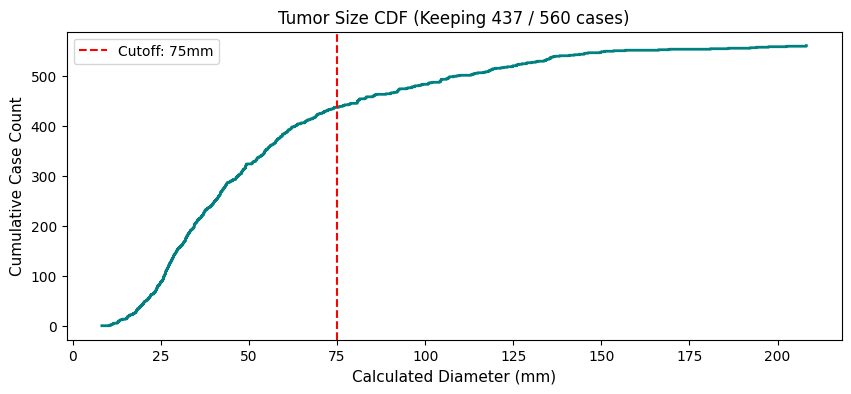

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('data/kits23_tumor_instance_data.csv')

def apply_threashold_and_plot(df, threshold):
    sorted_diameters = np.sort(df['calculated_diameter_mm'].dropna())
    y_vals = np.arange(1, len(sorted_diameters) + 1)

    # Plot CDF
    plt.figure(figsize=(10, 4))
    plt.step(sorted_diameters, y_vals, color='teal', where='post', linewidth=2)
    plt.axvline(x=threshold, color='red', linestyle='--', label=f'Cutoff: {threshold}mm')
    
    # Filter dataset
    kept_df = df[df['calculated_diameter_mm'] <= threshold].copy()
    
    plt.title(f"Tumor Size CDF (Keeping {len(kept_df)} / {len(df)} cases)")
    plt.xlabel("Calculated Diameter (mm)")
    plt.ylabel("Cumulative Case Count")
    plt.legend()
    plt.show()
    
    # return kept_df

apply_threashold_and_plot(df, 75)

Podczas konsultacji z medyczną strona tego projektu podjeliśmy decyzję o limice próbek do $<=75mm$, dyż dla większych ta skala nie ma zbytnio sensu -- skala służy do oceniania wycięcia nowotworu, przy nowotworach większych od 75mm wycina się całą nerkę.

W związku z czym uruchamiam ten skrypt:

In [17]:
import pandas as pd

TUMOR_INSTANCE_PATH = 'data/kits23_tumor_instance_data.csv'
TUMOR_SIZE_LIMIT_MM  = 75
ANNOTATION_PATH = f'data/annotation_empty_{TUMOR_SIZE_LIMIT_MM}mm.csv'

df = pd.read_csv(TUMOR_INSTANCE_PATH)
df = df[df['calculated_diameter_mm'] <= TUMOR_SIZE_LIMIT_MM]

# some tumors do not fit the RPN requirements
cases_to_drop = [
    'case_00458',
    'case_00466',
    'case_00517',
    'case_00524'
]

df = df[~df['case_id'].isin(cases_to_drop)]

# df.to_csv(ANNOTATION_PATH, index=False) # na pokaz tego nie trzeba
df.info()

<class 'pandas.DataFrame'>
Index: 434 entries, 0 to 559
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   tumor_id                434 non-null    str    
 1   case_id                 434 non-null    str    
 2   tumor_instance          434 non-null    str    
 3   kidney_instance         434 non-null    str    
 4   calculated_diameter_mm  434 non-null    float64
 5   spacing_z               434 non-null    float64
 6   spacing_y               434 non-null    float64
 7   spacing_x               434 non-null    float64
 8   position                162 non-null    str    
 9   invasion                162 non-null    str    
 10  radius_pts              162 non-null    float64
 11  approved_for_training   434 non-null    bool   
dtypes: bool(1), float64(5), str(6)
memory usage: 41.1 KB


Przygotowany w ten sposób plik .csv wrzucam do Google Sheets, i następnie udostępniam dla lekarzy do oznaczenia.
Kolumna `approved_for_training` została dodana aby lekarze mogli zaznaczyć nowotwory, które nie pasują do tego projektu.

Wyglądało to tak:

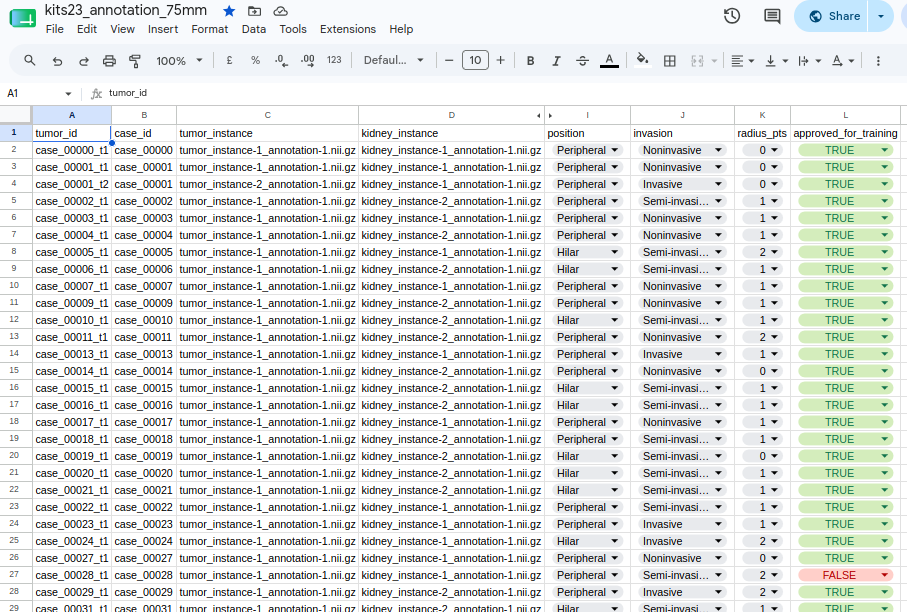

### Przygotowanie danych wejściowych
Jako że maski ze zbioru KiTS23 nie są stałych wymiarów (w osi z), trzeba je jakoś ustandardyzować.

Dodatkowo większość przestrzeni maski jest pusta, więc lepiej nie marnować na nią zasobów obliczeniowych.

W związku z tym zdecydowałem że dane zostaną przekształcone w macierze o stałych wymiarach
$(Z \times Y \times X \times 3)$, w któreych zawarte będą nowotwory i pojedyńcza nerka. Ostatnia oś odpowiada za one-hot encoding background-kidney-tumor.

Pytanie jest jakie powinny być "głębokości" tych pojecyńczych wymiarów?

Aby odpowiedzieć na to pytanie zrobiłem skrypt, który oblicza **bounding box** dla systm nerka-nowotwór oraz sama nerka.

In [18]:
from modules import data_preprocessing as dataPrep
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from termcolor import colored

KITS23_PATH = '/home/marcel/Repos/Data/kits23'
TUMOR_INSTANCE_DATA_PATH = 'data/annotation_empty_75mm.csv'
BBOX_PATH_KT = 'data/data_kt_bbox.csv'
BBOX_PATH_K = 'data/data_k_bbox.csv'


Dla układu nerka-nowotwór

<>:65: SyntaxWarning: invalid escape sequence '\m'
<>:65: SyntaxWarning: invalid escape sequence '\s'
<>:65: SyntaxWarning: invalid escape sequence '\m'
<>:65: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_128607/543589633.py:65: SyntaxWarning: invalid escape sequence '\m'
  ax.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')
/tmp/ipykernel_128607/543589633.py:65: SyntaxWarning: invalid escape sequence '\s'
  ax.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')
Calculating bounding boxes: 100%|██████████| 434/434 [20:34<00:00,  2.85s/it]


--- Mean + std ---
limit z = 123
limit y = 123
limit x = 116
--- Mean ---
limit z = 60
limit y = 103
limit x = 97


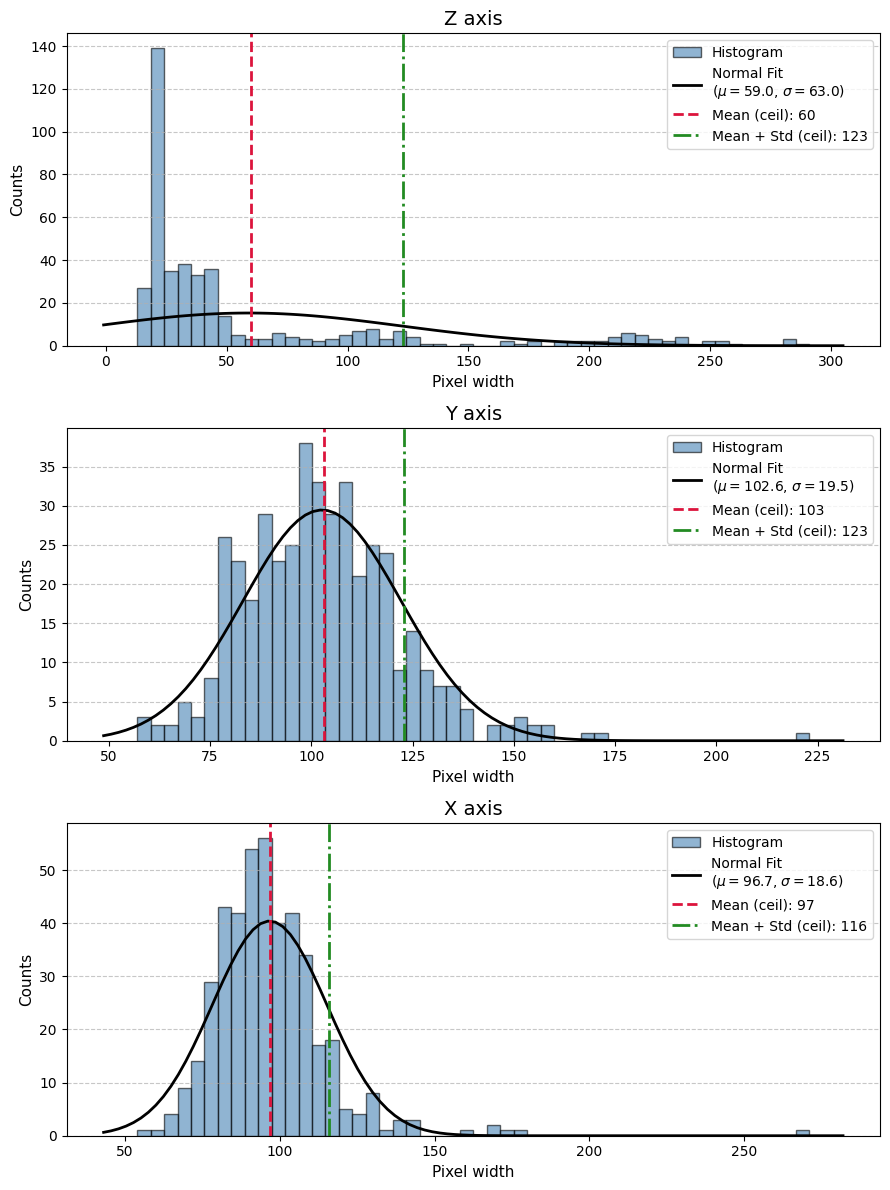

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from termcolor import colored

df = dataPrep.extract_tumor_kidney_bounding_boxes(TUMOR_INSTANCE_DATA_PATH, KITS23_PATH)
df.describe()

# Compute the values
# Mean + std limits
limit_z_std = np.ceil(df['size_z'].mean() + df['size_z'].std()).astype('int')
limit_y_std = np.ceil(df['size_y'].mean() + df['size_y'].std()).astype('int')
limit_x_std = np.ceil(df['size_x'].mean() + df['size_x'].std()).astype('int')

print(colored("--- Mean + std ---", "blue"))
print(f"limit z = {limit_z_std}")
print(f"limit y = {limit_y_std}")
print(f"limit x = {limit_x_std}")

# Mean limits
limit_z_mean = np.ceil(df['size_z'].mean()).astype('int')
limit_y_mean = np.ceil(df['size_y'].mean()).astype('int')
limit_x_mean = np.ceil(df['size_x'].mean()).astype('int')

print(colored("--- Mean ---", "blue"))
print(f"limit z = {limit_z_mean}")
print(f"limit y = {limit_y_mean}")
print(f"limit x = {limit_x_mean}")

# --- Plotting ---
# Create a single figure with 3 subplots stacked vertically
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(9, 12))

# Group the parameters to iterate cleanly over the axes
variables = [
    ('size_z', 'Z axis', limit_z_mean, limit_z_std),
    ('size_y', 'Y axis', limit_y_mean, limit_y_std),
    ('size_x', 'X axis', limit_x_mean, limit_x_std)
]

for ax, (col, title, mean_val, std_val) in zip(axes, variables):
    # Drop NaNs just in case to avoid issues with norm.fit()
    data = df[col].dropna()
    
    # 1. Plot histogram
    # Remove density=True. Capture the returned bins to calculate bin width.
    counts, bins, patches = ax.hist(data, bins=50, alpha=0.6, color='steelblue', edgecolor='black', label='Histogram')
    
    # Calculate bin width and total number of samples
    bin_width = bins[1] - bins[0]
    n_samples = len(data)
    
    # 2. Fit a normal distribution to the data
    mu, std = norm.fit(data)
    
    # Generate x-values for the fitted distribution curve
    xmin, xmax = ax.get_xlim()
    x = np.linspace(xmin, xmax, 100)
    
    # Scale the PDF up to match the count scale
    # Formula: PDF * Total Samples * Bin Width
    p = norm.pdf(x, mu, std) * n_samples * bin_width
    
    # Plot the fitted distribution curve
    ax.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')
    
    # 3. Add vertical lines for the computed mean and mean + std values
    ax.axvline(mean_val, color='crimson', linestyle='--', linewidth=2, label=f'Mean (ceil): {mean_val}')
    ax.axvline(std_val, color='forestgreen', linestyle='-.', linewidth=2, label=f'Mean + Std (ceil): {std_val}')
    
    # Formatting
    ax.set_title(title, fontsize=14)
    ax.set_ylabel('Counts') # Changed from Density to Count
    ax.set_xlabel('Pixel width')
    ax.legend(loc='upper right')
    ax.grid(axis='y', linestyle='--', alpha=0.7)

# Adjust layout so subplots don't overlap
plt.tight_layout()
plt.show()

Dla układu nerka (najbliższa)

<>:64: SyntaxWarning: invalid escape sequence '\m'
<>:64: SyntaxWarning: invalid escape sequence '\s'
<>:64: SyntaxWarning: invalid escape sequence '\m'
<>:64: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_128607/968253412.py:64: SyntaxWarning: invalid escape sequence '\m'
  ax.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')
/tmp/ipykernel_128607/968253412.py:64: SyntaxWarning: invalid escape sequence '\s'
  ax.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')
Calculating kidney bounding boxes: 100%|██████████| 434/434 [10:21<00:00,  1.43s/it]


--- Mean + std ---
limit z = 122
limit y = 122
limit x = 114
--- Mean ---
limit z = 59
limit y = 102
limit x = 96


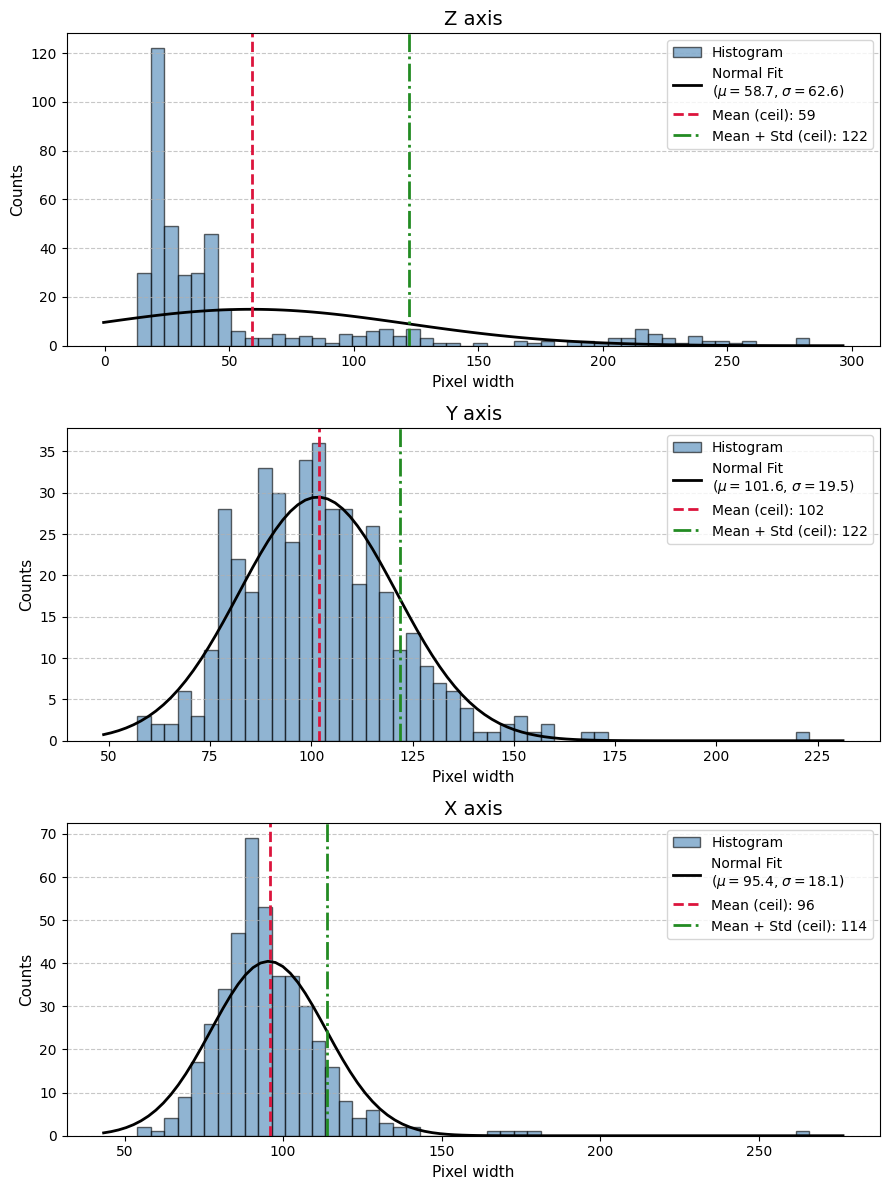

In [20]:
df = dataPrep.extract_kidney_bounding_boxes(TUMOR_INSTANCE_DATA_PATH, KITS23_PATH)

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from termcolor import colored

# Compute the values
# Mean + std limits
limit_z_std = np.ceil(df['size_z'].mean() + df['size_z'].std()).astype('int')
limit_y_std = np.ceil(df['size_y'].mean() + df['size_y'].std()).astype('int')
limit_x_std = np.ceil(df['size_x'].mean() + df['size_x'].std()).astype('int')

print(colored("--- Mean + std ---", "blue"))
print(f"limit z = {limit_z_std}")
print(f"limit y = {limit_y_std}")
print(f"limit x = {limit_x_std}")

# Mean limits
limit_z_mean = np.ceil(df['size_z'].mean()).astype('int')
limit_y_mean = np.ceil(df['size_y'].mean()).astype('int')
limit_x_mean = np.ceil(df['size_x'].mean()).astype('int')

print(colored("--- Mean ---", "blue"))
print(f"limit z = {limit_z_mean}")
print(f"limit y = {limit_y_mean}")
print(f"limit x = {limit_x_mean}")

# --- Plotting ---
# Create a single figure with 3 subplots stacked vertically
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(9, 12))

# Group the parameters to iterate cleanly over the axes
variables = [
    ('size_z', 'Z axis', limit_z_mean, limit_z_std),
    ('size_y', 'Y axis', limit_y_mean, limit_y_std),
    ('size_x', 'X axis', limit_x_mean, limit_x_std)
]

for ax, (col, title, mean_val, std_val) in zip(axes, variables):
    # Drop NaNs just in case to avoid issues with norm.fit()
    data = df[col].dropna()
    
    # 1. Plot histogram
    # Remove density=True. Capture the returned bins to calculate bin width.
    counts, bins, patches = ax.hist(data, bins=50, alpha=0.6, color='steelblue', edgecolor='black', label='Histogram')
    
    # Calculate bin width and total number of samples
    bin_width = bins[1] - bins[0]
    n_samples = len(data)
    
    # 2. Fit a normal distribution to the data
    mu, std = norm.fit(data)
    
    # Generate x-values for the fitted distribution curve
    xmin, xmax = ax.get_xlim()
    x = np.linspace(xmin, xmax, 100)
    
    # Scale the PDF up to match the count scale
    # Formula: PDF * Total Samples * Bin Width
    p = norm.pdf(x, mu, std) * n_samples * bin_width
    
    # Plot the fitted distribution curve
    ax.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')
    
    # 3. Add vertical lines for the computed mean and mean + std values
    ax.axvline(mean_val, color='crimson', linestyle='--', linewidth=2, label=f'Mean (ceil): {mean_val}')
    ax.axvline(std_val, color='forestgreen', linestyle='-.', linewidth=2, label=f'Mean + Std (ceil): {std_val}')
    
    # Formatting
    ax.set_title(title, fontsize=14)
    ax.set_ylabel('Counts') # Changed from Density to Count
    ax.set_xlabel('Pixel width')
    ax.legend(loc='upper right')
    ax.grid(axis='y', linestyle='--', alpha=0.7)

# Adjust layout so subplots don't overlap
plt.tight_layout()
plt.show()

Jak widać i dla `nerka-nowotwór` i dla `nerka`wyniki są praktycznie takie same. Jednak jest całkiem ważna różnica, w niektórych wypadkach, przy dużych, zewnętrznych nowotworach nerka jets przesunięta na bok. Takie wydapki mogą negatywnie wpłynąć na naszą sieć, ponieważ dla większości sieci, nerka jest w środku macierzu, a dla innych przesunięta.

Atypowa dystrybucja osi Z wynika z tego że różne maszyny CT mają róznej grubości "slices" (nie wiem jak to po polsku powiedzieć).

/tmp/ipykernel_128607/1073280087.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(counts.index.astype(str), rotation=15, ha='right')


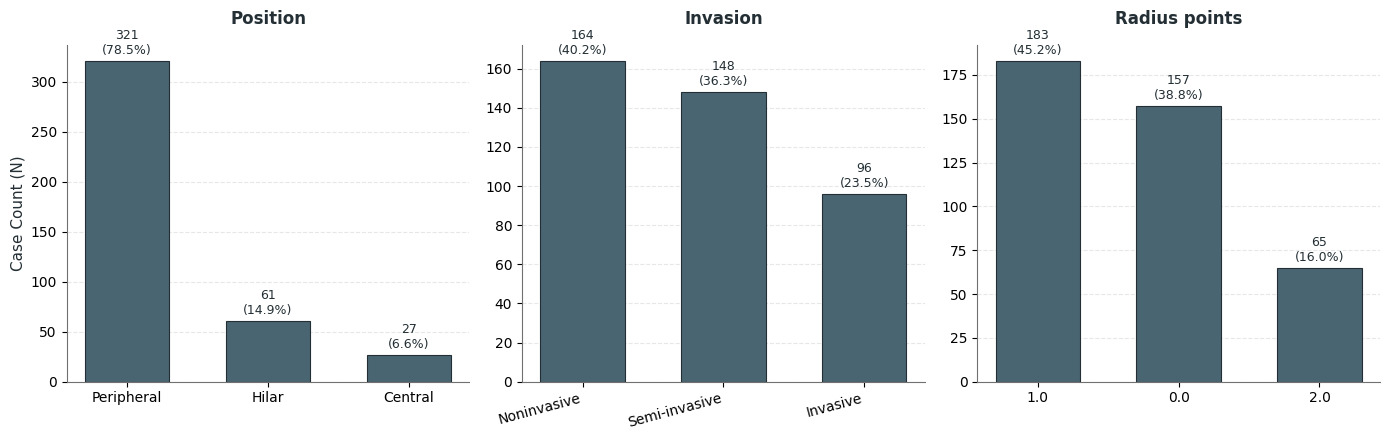

In [21]:
df = pd.read_csv("data/annotations_RPN_75mm_final.csv")

import matplotlib.pyplot as plt
import seaborn as sns

def plot_scientific_distribution(df):
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['xtick.labelsize'] = 10
    plt.rcParams['ytick.labelsize'] = 10
    plt.rcParams['axes.labelsize'] = 11
    
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=False)
    columns = ['position', 'invasion', 'radius_pts']
    titles = ['Position', 'Invasion', 'Radius points']
    
    academic_color = '#4A6572' 
    
    for i, col in enumerate(columns):
        ax = axes[i]
        
        counts = df[col].dropna().value_counts()
        total = counts.sum()
        
        # Plot bars
        bars = ax.bar(counts.index.astype(str), counts.values, color=academic_color, width=0.6, edgecolor='#232F34', linewidth=0.8)
        
        # Remove top and right borders (spines) for a clean scientific look
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#707070')
        ax.spines['bottom'].set_color('#707070')
        
        # Title and Labels
        ax.set_title(titles[i], fontsize=12, weight='bold', pad=15, color='#232F34')
        ax.set_ylabel('Case Count (N)' if i == 0 else '', color='#232F34')
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        ax.set_axisbelow(True)
        
        # Add exact Count and Percentage above each bar
        for bar in bars:
            height = bar.get_height()
            percentage = (height / total) * 100
            ax.annotate(f'{int(height)}\n({percentage:.1f}%)',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=9, color='#232F34')
            
        # Rotate x-labels slightly if they are long words
        if col == 'invasion':
            ax.set_xticklabels(counts.index.astype(str), rotation=15, ha='right')

    plt.tight_layout()
    plt.show()

# Run the visualizer
plot_scientific_distribution(df)

W związku z powyższą analizą zrobiłem skrypt i odpowiednią funkcję do tworzenie danych do uczenia.

Funkcja ta ma wiele opcji, ale w aktualej konfiguracji oblicza bounding box dla nerki $+ 10\%$ marginesu z każdej strony, następnie upcscaluje lub downscaluje ten bounding box (o różny współczynnik w każdą stronę aby wypełnić kształt) do rozmiarów policzonyc hwcześniej (aby nie stracić detali) i one-hot encod-uję.

W ten sposób mamy mamy zbiór danych wejściowych, które mają stały wymiar.
Dodatkowo obok tych danych dołączyłem oznaczenia (dane wyjściowe), odpowiadające za parametry **position** i **invasion** (radius będzie liczony numerycznie) które są w formacie one-hot, więc 6 wartości 0-1.

Dodatkowo w każdym wygenerowanym w ten sposób zbiorze danych zamieszczone są pliki metadata, opisujące parametry stworzenia tego dataset-u, podział danych na foldy (kfold split z zachowaniem dystrybucji)

K-fold (z zachowaniem rozkładu grup) został wykorzystany ponieważ mam relatywnie mały zbiór danych oraz niektóre klasy są mało reprezentowane (position), w związku z tym wykorzystuję też przy uczeniu dynamiczne wagi.

`compile_dataset.py`:

In [22]:
import pandas as pd
from pathlib import Path
from modules import data_preprocessing as dataPrep
from modules import plotting_functions as plf
from termcolor import colored

# --- CONFIGURATIONS ---
ANNOTATION_PATH = 'data/annotations_RPN_75mm_final.csv'
KITS23_DATASET_PATH = '/home/marcel/Repos/Data/kits23'
BASE_OUTPUT_DIR = Path('/home/marcel/Repos/Data/kits23_processed')

# Define target experiments to generate
TARGET_SHAPES = [(123, 123, 116)] 
# https://www.ncbi.nlm.nih.gov/books/NBK482385/?utm_source=chatgpt.com
# "Typical dimensions include a length of 10 to 12 cm, a width of 5 to 7 cm, and a thickness of 3 to 5 cm, comparable in size to a closed fist."
# So proportion should be ~11:6:4
# TARGET_SHAPES.append((110, 60, 40))
# TARGET_SHAPES.append((85, 45, 30))
# TARGET_SHAPES.append((55, 30, 20))
BBOX_STRATEGIES = ['kidney'] # alternatywnie kidney-tumor
N_SPLITS = 5

# --- LOAD & CLEAN DATA ---
df = pd.read_csv(ANNOTATION_PATH)
df = df[df['approved_for_training']]  # remove rejected cases
# df = df.iloc[:10] # for prototyping
df = df.dropna(subset=['case_id', 'tumor_instance', 'kidney_instance', 'position', 'invasion', 'radius_pts'])

# --- GENERATE DETERMINISTIC K-FOLD SPLITS ---
df_master_splits = dataPrep.generate_train_validation_split(df, n_splits=N_SPLITS)

# Save this out as a master split reference for audit trails
df_master_splits.to_csv(BASE_OUTPUT_DIR / "kfold_master_splits.csv", index=False)
print(f"\nSaved Stratified Group K-Fold Splits to {BASE_OUTPUT_DIR}/kfold_master_splits.csv")

# --- LOOP AND COMPILE DATASETS ---
print(colored("\nDataset generation:", "blue", attrs=["bold"]))
print(f"Shapes: {TARGET_SHAPES}")
print(f"Bbox strategies: {BBOX_STRATEGIES}\n")

for target_shape in TARGET_SHAPES:
    for bbox_strat in BBOX_STRATEGIES:
        # Generate shape description string
        shape_str = "_".join(str(n) for n in target_shape)
        dir_name = f"kits_dataset_{shape_str}_{bbox_strat}"
        
        compiled_dataset_dir = BASE_OUTPUT_DIR / dir_name
        dataset_figures_dir = BASE_OUTPUT_DIR / f"figures_{dir_name}"
        
        print(f"\nProcessing: {dir_name}")
        
        # Generate the dataset
        dataPrep.prepare_cnn_data(
            df=df.copy(), 
            kits_dir=KITS23_DATASET_PATH, 
            out_dir=compiled_dataset_dir, 
            target_shape=target_shape, 
            bbox=bbox_strat, 
            preserve_geometry=False
        )
        
        # Save a localized copy of the split map matching exactly what's inside this directory
        df_master_splits.to_csv(compiled_dataset_dir / "dataset_splits.csv", index=False)
        
        # --- GENERATE DIAGNOSTIC VIDEOS ---
        # print(f"Generating videos...")
        # dirs = [p for p in compiled_dataset_dir.iterdir() if p.is_dir()]
        # for d in dirs:
        #     plf.generate_tumor_video_from_npy(d, dataset_figures_dir)

print(colored("\nDataset generation complete.", "blue", attrs=["bold"]))


--- Fold 0 Created ---
	Train samples: 317 | Validation samples: 79
	Val Class Dist: {'Peripheral': 0.7848101265822784, 'Hilar': 0.1518987341772152, 'Central': 0.06329113924050633}

--- Fold 1 Created ---
	Train samples: 316 | Validation samples: 80
	Val Class Dist: {'Peripheral': 0.775, 'Hilar': 0.15, 'Central': 0.075}

--- Fold 2 Created ---
	Train samples: 317 | Validation samples: 79
	Val Class Dist: {'Peripheral': 0.7848101265822784, 'Hilar': 0.1518987341772152, 'Central': 0.06329113924050633}

--- Fold 3 Created ---
	Train samples: 317 | Validation samples: 79
	Val Class Dist: {'Peripheral': 0.7721518987341772, 'Hilar': 0.1518987341772152, 'Central': 0.0759493670886076}

--- Fold 4 Created ---
	Train samples: 317 | Validation samples: 79
	Val Class Dist: {'Peripheral': 0.7848101265822784, 'Hilar': 0.1518987341772152, 'Central': 0.06329113924050633}

Saved Stratified Group K-Fold Splits to /home/marcel/Repos/Data/kits23_processed/kfold_master_splits.csv

Dataset generation:
Shape

Preparing CNN data: 100%|██████████| 396/396 [14:18<00:00,  2.17s/it]


Dataset generation complete.


## Kod wczytujący dane i robiący rysunki
jest w kodzie powyżej w sekcji "--- GENERATE DIAGNOSTIC VIDEOS ---", funkcja `plf.generate_tumor_video_from_npy` ale jest to bardzo czasochłonne i zrobiłem to już raz, to co wygenerowałem znajdzie Pan tutaj - https://drive.google.com/drive/folders/1JDYnAJW01QC1UKJaawZp9O8RbTpDZgRF?usp=sharing, całkiem fajnie moim zdanime wyszły.



## Trening modelu
Planuję przez wakacje zwiększyć celność tego modelu, ale to pewnie zajmie trochę.

Z trening odpowiada `train.py` o treści:
```python
import os
# Suppress standard TensorFlow INFO and WARNING logs (set to '3' to mute errors too, '2' filters info/warnings)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'


import argparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import tensorflow as tf
import keras
from termcolor import colored
import json
import gc

# import custom modules
from modules import plotting_functions as plf
from modules import data_preprocessing as dataPrep
from modules import model_functions as mod

def parse_arguments():
    parser = argparse.ArgumentParser(description="Train 3D CNN on KiTS23 Preprocessed Dataset")
    parser.add_argument('--data_dir', type=str, required=True, help="Path to the compiled training dataset directory")
    parser.add_argument('--out_dir', type=str, default="./training_outputs", help="Directory to saved models and figures")
    parser.add_argument('--epochs', type=int, default=50)
    parser.add_argument('--batch_size', type=int, default=4)
    parser.add_argument('--n_folds', type=int, default=5, help="Total number of cross-validation folds")
    parser.add_argument('--save_model', action='store_true', help="Flag to save the best model")
    parser.add_argument('--workers', type=int, default=4, help="Number of CPU workers for data generation")

    return parser.parse_args()

def main():
    args = parse_arguments()

    out_dir = Path(args.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    print(colored(f"--- KiTS23 Processed Data Model Training ---", "blue", attrs=["bold"]))
    print(f"Dataset Directory: {args.data_dir}")
    print(f"Batch Size: {args.batch_size} | Epochs: {args.epochs} | Total Folds: {args.n_folds}")

    # Determine the input shape from the dataset directory metadata
    metadata_path = Path(args.data_dir) / "dataset_metadata.json"
    if not metadata_path.exists():
        raise FileNotFoundError(f"Could not find dataset metadata at: {metadata_path}")
    
    with open(metadata_path, 'r') as f:
        metadata = json.load(f)

    # extract the shape
    target_shape = metadata["target_shape"]
    input_shape = (target_shape[0], target_shape[1], target_shape[2], 3)
    print(f"Loaded target shape from metadata {metadata_path}")

    # NOTE need to add a print saying how many out of all folds are being processed
    for fold_no in range(args.n_folds):
        print(f"\n{'='*40}")
        print(colored(f"\tProcessing fold {fold_no}")) 
        print(f"{'='*40}\n")

        fold_out_dir = out_dir / f"fold_{fold_no}"
        fold_out_dir.mkdir(exist_ok=True)

        # Get paths
        train_paths, val_paths = dataPrep.get_train_validation_paths(args.data_dir, fold_no)

        # Extract class weights
        class_weights = dataPrep.get_keras_class_weights(train_paths)

        # Generator
        train_generator = dataPrep.KITSDataGenerator(
            train_paths,
            batch_size=args.batch_size,
            augment=True,
            shuffle=True,
            max_translation=[10,10,10]
        )

        val_generator = dataPrep.KITSDataGenerator(
            val_paths,
            batch_size=args.batch_size,
            augment=False,
            shuffle=False # so that every validation runs identically
        )

        # Build and compile model
        model = mod.build_model(input_shape=input_shape)
        if fold_no == 0:
            model.summary() # print summary only once

        mod.train_model(model, train_generator, val_generator, class_weights, args, fold_no, fold_out_dir)

        plf.plot_and_evaluate(fold_out_dir, fold_no)

        # HPC safety precautions
        del model
        del train_generator
        del val_generator
        keras.backend.clear_session()
        gc.collect()

    plf.plot_and_evaluate_all_folds(args.out_dir)

if __name__ == "__main__":
    main()
```
 

In [23]:
# skrypt jest przygotowany w taki sposób aby łatwo go uruchamiać z konsoli (np. na ICM).

%cd /home/marcel/Repos/kidney-tumor-radiomics

!python3 train.py --data_dir /home/marcel/Repos/Data/kits23_processed/kits_dataset_123_123_116_kidney --epochs 30 --n_folds 3

/home/marcel/Repos/kidney-tumor-radiomics
--- KiTS23 Processed Data Model Training ---
Dataset Directory: /home/marcel/Repos/Data/kits23_processed/kits_dataset_123_123_116_kidney
Batch Size: 4 | Epochs: 30 | Total Folds: 3
Loaded target shape from metadata /home/marcel/Repos/Data/kits23_processed/kits_dataset_123_123_116_kidney/dataset_metadata.json

	Processing fold 0

Loaded paths for Fold 0 from /home/marcel/Repos/Data/kits23_processed/kits_dataset_123_123_116_kidney
I0000 00:00:1782413827.282452  135717 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5788 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060 SUPER, pci bus id: 0000:09:00.0, compute capability: 7.5
Model: "RPN_classification_model"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)  

## rysunki ilustrujące wydajność modelu na danych testowych
Ploty automatycznie generowane po uczedniu, oddzielne dla każdego fold-u:

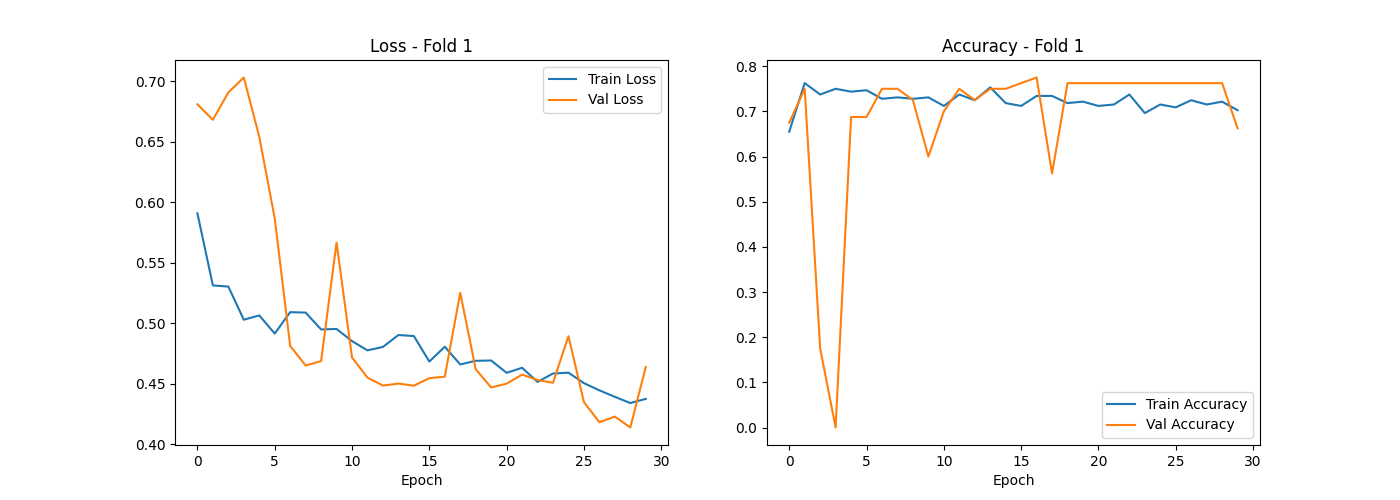

oraz na koniec, wspólne:

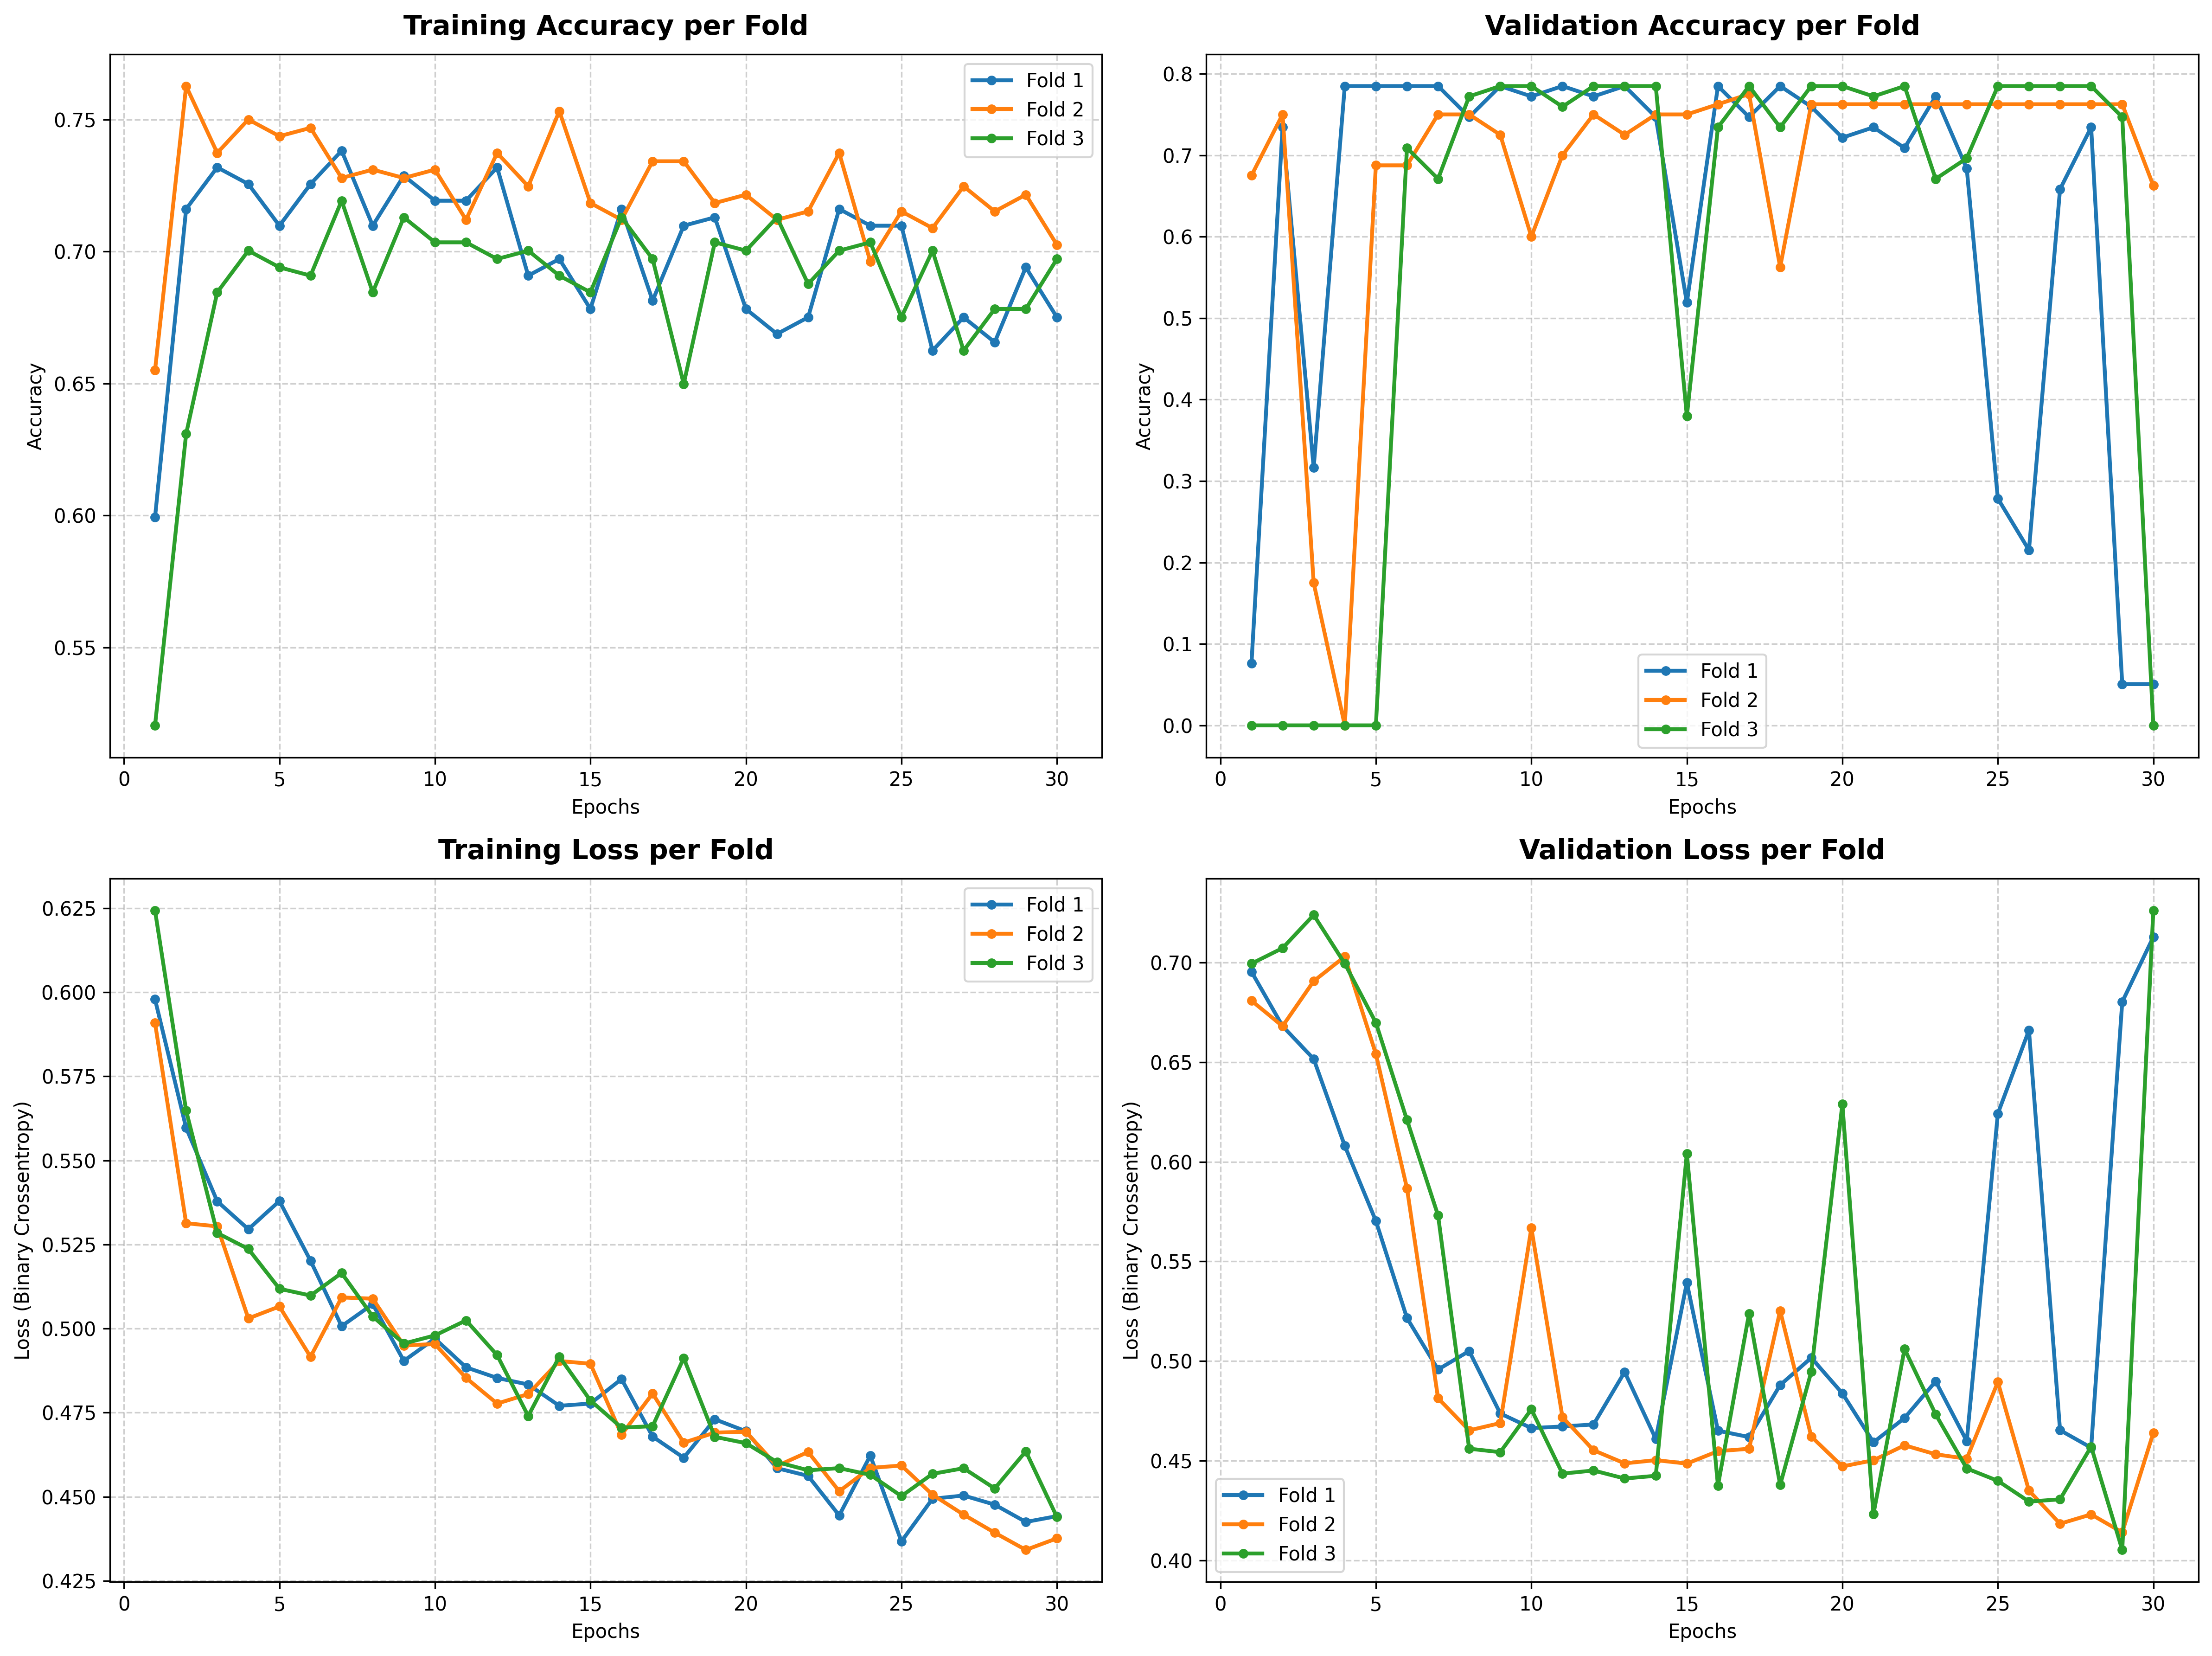

Uczenie modelu przez większą ilość epok sprawiało że wcześnie kończyła uczenie (jak spróbowałem)

-> aby poprawić celność trzeba będzie zmienić architekturę, dane wejściowe albo generator.

Jak widać na poniższym grafie, który jest po innej iteracji uczenia którą zrobiłem wcześniej, model traci skuteczność na danych walidacyjnych po wcześniejszych dobrych wynikach.

Moim zdaniem model overfituje, będę jeszcze przez wakacje nad tym pracował.

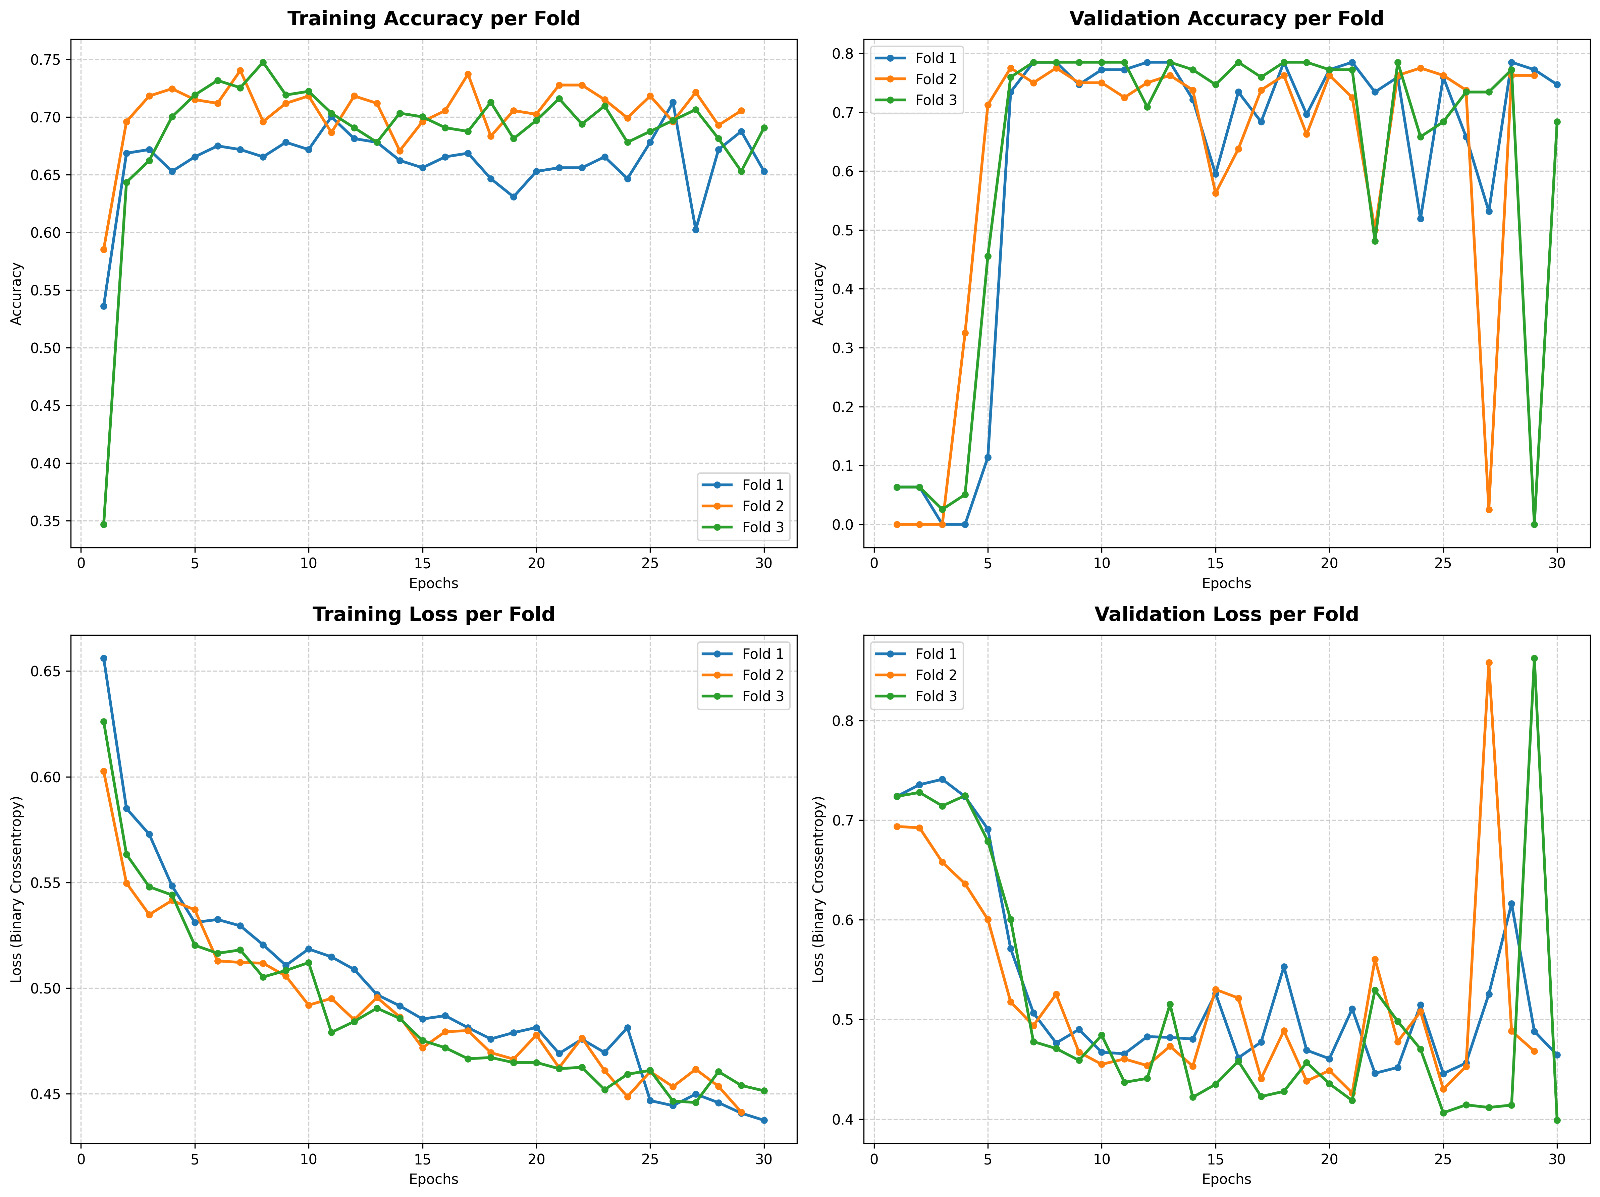